In [24]:
from pathlib import Path

import pandas as pd

data_dir = Path.cwd().parent / "data" / "raw"

train = pd.read_csv(data_dir / "train.csv")
test = pd.read_csv(data_dir / "test.csv")


print("Train shape:", train.shape)
print("Test shape:", test.shape)

print("\nTrain columns:", train.columns[:5].tolist())
print("Test columns:", test.columns[:5].tolist())

print("\nTarget in train:", "target" in train.columns)
print("Target in test:", "target" in test.columns)

train_features = set(train.columns) - {"ID_code", "target"}
test_features = set(test.columns) - {"ID_code"}

print("\nFeature sets match:", train_features == test_features)

Train shape: (200000, 202)
Test shape: (200000, 201)

Train columns: ['ID_code', 'target', 'var_0', 'var_1', 'var_2']
Test columns: ['ID_code', 'var_0', 'var_1', 'var_2', 'var_3']

Target in train: True
Target in test: False

Feature sets match: True


In [25]:
print("Unique train IDs: ", train["ID_code"].is_unique)
print("Unique test IDs: ", test["ID_code"].is_unique)

train_ids = set(train["ID_code"])
test_ids = set(test["ID_code"])

print("Train/Test ID overlap: ", len(train_ids & test_ids))


Unique train IDs:  True
Unique test IDs:  True
Train/Test ID overlap:  0


In [26]:
train.head()

,ID_code,target,var_0,var_1,var_2,var_3,var_4,var_5,var_6,var_7,...,var_190,var_191,var_192,var_193,var_194,var_195,var_196,var_197,var_198,var_199
0,train_0,0,8.9255,-6.7863,11.9081,5.0930,11.4607,-9.2834,5.1187,18.6266,...,4.4354,3.9642,3.1364,1.6910,18.5227,-2.3978,7.8784,8.5635,12.7803,-1.0914
1,train_1,0,11.5006,-4.1473,13.8588,5.3890,12.3622,7.0433,5.6208,16.5338,...,7.6421,7.7214,2.5837,10.9516,15.4305,2.0339,8.1267,8.7889,18.3560,1.9518
2,train_2,0,8.6093,-2.7457,12.0805,7.8928,10.5825,-9.0837,6.9427,14.6155,...,2.9057,9.7905,1.6704,1.6858,21.6042,3.1417,-6.5213,8.2675,14.7222,0.3965
3,train_3,0,11.0604,-2.1518,8.9522,7.1957,12.5846,-1.8361,5.8428,14.9250,...,4.4666,4.7433,0.7178,1.4214,23.0347,-1.2706,-2.9275,10.2922,17.9697,-8.9996
4,train_4,0,9.8369,-1.4834,12.8746,6.6375,12.2772,2.4486,5.9405,19.2514,...,-1.4905,9.5214,-0.1508,9.1942,13.2876,-1.5121,3.9267,9.5031,17.9974,-8.8104


In [27]:
train["target"].value_counts()

target
0    179902
1     20098
Name: count, dtype: int64

In [28]:
train["target"].value_counts(normalize= True)

target
0    0.89951
1    0.10049
Name: proportion, dtype: float64

In [29]:
train.isna().sum().sum()

np.int64(0)

In [30]:
missing_counts = train.isna().sum()
missing_columns = missing_counts[missing_counts > 0]

print(missing_columns.index.tolist())

[]


### Data Quality Assessment

**Objective:** Assess the integrity and consistency of the feature space before preprocessing and model development.

**Methodology:** Examine duplicate feature vectors independently of customer identifiers and target labels, identify non-numeric predictors, and check the test dataset for missing values.

**Modeling Consideration:** Data quality findings will guide subsequent preprocessing decisions. Duplicate observations will not be removed automatically, and transformations will only be introduced when supported by the data characteristics and modeling requirements.

In [31]:
feature_columns = [f"var_{i}" for i in range(200)]

train_duplicates = train.duplicated(
    subset=feature_columns
).sum()

test_duplicates = test.duplicated(
    subset=feature_columns
).sum()

train_non_numeric = train[feature_columns].select_dtypes(
    exclude="number"
).columns.tolist()

test_non_numeric = test[feature_columns].select_dtypes(
    exclude="number"
).columns.tolist()

test_missing = test.isna().sum().sum()

print(f"Train duplicate feature rows: {train_duplicates}")
print(f"Test duplicate feature rows: {test_duplicates}")
print(f"Train non-numeric features: {train_non_numeric}")
print(f"Test non-numeric features: {test_non_numeric}")
print(f"Test missing values: {test_missing}")

Train duplicate feature rows: 0
Test duplicate feature rows: 0
Train non-numeric features: []
Test non-numeric features: []
Test missing values: 0


### Findings and Interpretation

The initial data quality assessment produced the following findings:

- No duplicate feature vectors were detected within either the training or test dataset.
- All 200 predictor variables are numeric.
- Neither dataset contains missing values.

These findings indicate that no immediate duplicate removal, categorical encoding, or missing-value imputation is required.

**Modeling Decision:** Retain the original feature values and avoid unnecessary preprocessing. Model-specific transformations, such as feature scaling, will be considered when selecting the baseline algorithm.

**Limitation:** These checks do not establish the absence of outliers, distribution shifts, or data leakage.

In [32]:
from sklearn.model_selection import train_test_split

X = train[feature_columns]
y = train["target"]

X_train, X_valid, y_train, y_valid = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42,
)

print("Training shape:", X_train.shape)
print("Validation shape:", X_valid.shape)

print("Training positive rate:", y_train.mean())
print("Validation positive rate:", y_valid.mean())

Training shape: (160000, 200)
Validation shape: (40000, 200)
Training positive rate: 0.1004875
Validation positive rate: 0.1005


In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

baseline_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000),
)

baseline_model.fit(X_train, y_train)

valid_proba = baseline_model.predict_proba(X_valid)[:, 1]

valid_auc = roc_auc_score(y_valid, valid_proba)

print(f"Baseline Validation ROC-AUC: {valid_auc:.4f}")

Baseline Validation ROC-AUC: 0.8599


In [34]:
class_order = baseline_model.classes_

sample_probabilities = baseline_model.predict_proba(
    X_valid.iloc[:3]
)

print("Class order:", class_order)
print("Predicted probabilities:")
print(sample_probabilities)

Class order: [0 1]
Predicted probabilities:
[[0.99548562 0.00451438]
 [0.93968691 0.06031309]
 [0.99373751 0.00626249]]


In [35]:
from sklearn.metrics import roc_auc_score

train_proba = baseline_model.predict_proba(X_train)[:, 1]
valid_proba = baseline_model.predict_proba(X_valid)[:, 1]

train_auc = roc_auc_score(y_train, train_proba)
valid_auc = roc_auc_score(y_valid, valid_proba)

auc_gap = train_auc - valid_auc

print(f"Training ROC-AUC: {train_auc:.4f}")
print(f"Validation ROC-AUC: {valid_auc:.4f}")
print(f"Generalization Gap: {auc_gap:.4f}")

Training ROC-AUC: 0.8613
Validation ROC-AUC: 0.8599
Generalization Gap: 0.0014


### Baseline Model: Logistic Regression

**Objective:** Establish a reproducible baseline for predicting customer transaction behavior.

**Methodology:** A Logistic Regression classifier was trained using 200 numerical predictors. StandardScaler was integrated into a Pipeline to prevent preprocessing leakage. The dataset was divided into stratified training (80%) and validation (20%) subsets using a fixed random seed of 42.

**Results:**

| Metric | ROC-AUC |
|---|---:|
| Training | 0.8613 |
| Validation | 0.8599 |
| Generalization Gap | 0.0014 |

**Interpretation:** The baseline demonstrates useful discriminatory performance, with a small training-validation gap. No substantial overfitting is evident on the current holdout split. However, a small gap alone does not rule out underfitting or guarantee performance on future data.

**Modeling Decision:** Retain Logistic Regression as the reference baseline. Evaluate a nonlinear model using the same validation split to determine whether additional model complexity improves predictive performance.

In [36]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score

lgbm_model = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=50,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

lgbm_model.fit(
    X_train,
    y_train,
    eval_set=[(X_valid, y_valid)],
    callbacks=[lgb.early_stopping(stopping_rounds=50)],
)

lgbm_train_proba = lgbm_model.predict_proba(X_train)[:, 1]
lgbm_valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]

lgbm_train_auc = roc_auc_score(y_train, lgbm_train_proba)
lgbm_valid_auc = roc_auc_score(y_valid, lgbm_valid_proba)

print(f"Best iteration: {lgbm_model.best_iteration_}")
print(f"Training ROC-AUC: {lgbm_train_auc:.4f}")
print(f"Validation ROC-AUC: {lgbm_valid_auc:.4f}")
print(f"Generalization Gap: {lgbm_train_auc - lgbm_valid_auc:.4f}")

/Users/ebrietas/Santander-Customer-Transaction-Prediction/.venv/lib/python3.12/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 50 rounds
Early stopping, best iteration is:
[1079]	valid_0's auc: 0.892809
Best iteration: 1079
Training ROC-AUC: 0.9608
Validation ROC-AUC: 0.8928
Generalization Gap: 0.0680


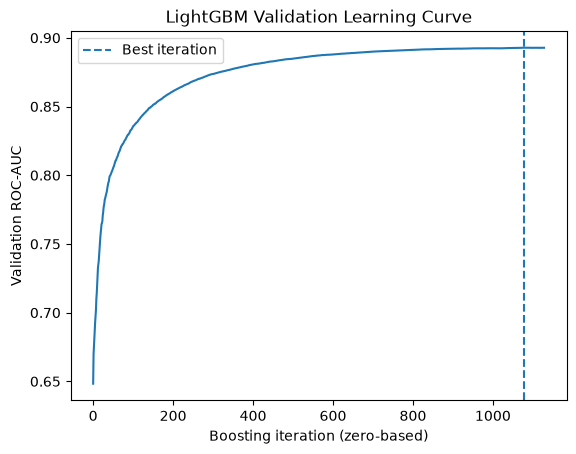

In [37]:
import matplotlib.pyplot as plt

validation_auc_history = lgbm_model.evals_result_["valid_0"]["auc"]

plt.plot(validation_auc_history)
plt.axvline(
    x=lgbm_model.best_iteration_ - 1,
    linestyle="--",
    label="Best iteration",
)
plt.xlabel("Boosting iteration (zero-based)")
plt.ylabel("Validation ROC-AUC")
plt.title("LightGBM Validation Learning Curve")
plt.legend()
plt.show()

In [38]:
auc_history = lgbm_model.evals_result_["valid_0"]["auc"]

auc_at_400 = auc_history[399]
auc_at_best = auc_history[lgbm_model.best_iteration_ - 1]

improvement = auc_at_best - auc_at_400

print(f"Validation AUC at iteration 400: {auc_at_400:.6f}")
print(f"Best Validation AUC: {auc_at_best:.6f}")
print(f"AUC improvement: {improvement:.6f}")

Validation AUC at iteration 400: 0.880544
Best Validation AUC: 0.892809
AUC improvement: 0.012264


In [39]:
regularized_model = lgb.LGBMClassifier(
    objective="binary",
    metric="auc",
    n_estimators=1500,
    learning_rate=0.05,
    num_leaves=7,
    min_child_samples=50,
    random_state=42,
    n_jobs=-1,
    verbosity=-1,
)

regularized_model.fit(
    X_train,
    y_train,
    eval_X=X_valid,
    eval_y=y_valid,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
)

regularized_train_proba = regularized_model.predict_proba(X_train)[:, 1]
regularized_valid_proba = regularized_model.predict_proba(X_valid)[:, 1]

regularized_train_auc = roc_auc_score(y_train, regularized_train_proba)
regularized_valid_auc = roc_auc_score(y_valid, regularized_valid_proba)

print(f"Best iteration: {regularized_model.best_iteration_}")
print(f"Training ROC-AUC: {regularized_train_auc:.4f}")
print(f"Validation ROC-AUC: {regularized_valid_auc:.4f}")
print(f"Generalization Gap: {regularized_train_auc - regularized_valid_auc:.4f}")

Best iteration: 1500
Training ROC-AUC: 0.9372
Validation ROC-AUC: 0.8939
Generalization Gap: 0.0432


In [40]:
from sklearn.base import clone

extended_model = clone(regularized_model)
extended_model.set_params(n_estimators=3000)

extended_model.fit(
    X_train,
    y_train,
    eval_X=X_valid,
    eval_y=y_valid,
    callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)],
)

extended_train_proba = extended_model.predict_proba(X_train)[:, 1]
extended_valid_proba = extended_model.predict_proba(X_valid)[:, 1]

extended_train_auc = roc_auc_score(y_train, extended_train_proba)
extended_valid_auc = roc_auc_score(y_valid, extended_valid_proba)

print(f"Best iteration: {extended_model.best_iteration_}")
print(f"Training ROC-AUC: {extended_train_auc:.4f}")
print(f"Validation ROC-AUC: {extended_valid_auc:.4f}")
print(f"Generalization Gap: {extended_train_auc - extended_valid_auc:.4f}")

Best iteration: 1726
Training ROC-AUC: 0.9417
Validation ROC-AUC: 0.8945
Generalization Gap: 0.0473


In [41]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate

cv_model = clone(extended_model).set_params(
    n_estimators=extended_model.best_iteration_
)

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42,
)

cv_results = cross_validate(
    cv_model,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    n_jobs=1,
)

print("Training AUC:", cv_results["train_score"])
print("Validation AUC:", cv_results["test_score"])
print(f"Mean CV AUC: {cv_results['test_score'].mean():.4f}")
print(f"Std CV AUC: {cv_results['test_score'].std():.4f}")

Training AUC: [0.95547401 0.95589778 0.955981  ]
Validation AUC: [0.89392466 0.8937503  0.89176766]
Mean CV AUC: 0.8931
Std CV AUC: 0.0010


In [42]:
baseline_cv_results = cross_validate(
    clone(baseline_model),
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=1,
)

print("Baseline CV AUC:", baseline_cv_results["test_score"])
print(f"Mean CV AUC: {baseline_cv_results['test_score'].mean():.4f}")
print(f"Std CV AUC: {baseline_cv_results['test_score'].std():.4f}")

Baseline CV AUC: [0.85955151 0.85992341 0.85764042]
Mean CV AUC: 0.8590
Std CV AUC: 0.0010


### Model Comparison and Selection

**Objective**

Compare the predictive performance and stability of Logistic Regression and LightGBM to identify the most promising model for customer transaction prediction.

**Methodology**

Both models were evaluated using the same three-fold Stratified Cross-Validation procedure on the training partition, with ROC-AUC as the primary evaluation metric.

- Logistic Regression was evaluated within a pipeline containing StandardScaler.
- LightGBM was evaluated using 7 leaves per tree and 1,726 boosting iterations, based on the preceding holdout experiments.
- The mean and standard deviation of validation ROC-AUC were used to assess performance and stability.

**Results**

| Model | Mean CV ROC-AUC | Std CV ROC-AUC |
|---|---:|---:|
| Logistic Regression | 0.8590 | 0.0010 |
| LightGBM | 0.8931 | 0.0010 |

**Findings and Interpretation**

LightGBM outperformed Logistic Regression by approximately 0.0341 ROC-AUC points while exhibiting similarly low variability across the three folds.

The results suggest that nonlinear modeling provides additional predictive value for this dataset.

However, LightGBM also demonstrated a larger training-validation performance gap, indicating greater sensitivity to the training data and a need for continued attention to overfitting.

**Modeling Decision**

LightGBM is selected as the provisional preferred model based on its superior cross-validation performance and consistent results across folds.

Further extensive hyperparameter tuning is not prioritized at this stage, as the current experiments provide sufficient evidence to proceed with model finalization and reproducibility checks.

**Limitations**

The LightGBM configuration was selected using a previously examined holdout validation set. Therefore, the evaluation results should not be interpreted as a completely independent estimate of deployment performance.

Additionally, three-fold cross-validation provides only limited evidence of stability, and the available unlabeled test dataset cannot be used to calculate final ROC-AUC.